# Studi Komparatif Model Generatif (Deep Learning D6421 Sesi 07)
Notebook ini menjalankan seluruh eksperimen komparatif model generatif dan pembuktian batasan MLP Classifier pada dataset Fashion-MNIST.

In [1]:
# 1. Periksa GPU & Lingkungan PyTorch
import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Device Name:', torch.cuda.get_device_name(0))
device = 'cuda' if torch.cuda.is_available() else 'cpu'

PyTorch Version: 2.14.0+cpu
CUDA Available: False


In [2]:
# 2. Eksperimen Pembuktian Batasan MLP Classifier (Tahap 1 - 5)
from exp_mlp_limits import run_mlp_experiments
run_mlp_experiments(device=device)

Device: cpu


100.0%
100.0%
100.0%
100.0%


Training MLP classifier...
Epoch 01/15 - Train Acc: 78.89% - Val Acc: 83.29%
Epoch 05/15 - Train Acc: 88.71% - Val Acc: 87.80%
Epoch 10/15 - Train Acc: 90.64% - Val Acc: 88.36%
Epoch 15/15 - Train Acc: 91.94% - Val Acc: 88.96%
Test Accuracy: 88.64%
Melatih decoder dari fitur laten MLP beku...
Decoder Epoch 05/10 - Loss: 0.02034
Decoder Epoch 10/10 - Loss: 0.01851
Figur batasan MLP tersimpan di figures/


In [3]:
# 3. Pelatihan 6 Model Generatif (Vanilla AE, Sparse AE, VAE, Vanilla GAN, DCGAN, DDPM)
from train_generative import train_all_models
# default 15 epoch, Anda dapat menyesuaikan sesuai kebutuhan
train_all_models(device=device, epochs=15)

Device: cpu
Training Vanilla Autoencoder...
Vanilla AE | Epoch 01/15 - loss: 0.03493 (8.7s)
Vanilla AE | Epoch 05/15 - loss: 0.01246 (9.4s)
Vanilla AE | Epoch 10/15 - loss: 0.00999 (9.8s)
Vanilla AE | Epoch 15/15 - loss: 0.00898 (10.1s)
Training Sparse Autoencoder...
Sparse AE  | Epoch 01/15 - loss: 0.03433 (9.3s)
Sparse AE  | Epoch 05/15 - loss: 0.01254 (10.0s)
Sparse AE  | Epoch 10/15 - loss: 0.01001 (10.4s)
Sparse AE  | Epoch 15/15 - loss: 0.00895 (23.4s)
Training VAE...
VAE        | Epoch 01/15 - loss: 300.41908 (26.4s)
VAE        | Epoch 05/15 - loss: 250.12879 (26.2s)
VAE        | Epoch 10/15 - loss: 244.49404 (11.2s)
VAE        | Epoch 15/15 - loss: 242.69968 (30.0s)
Training Vanilla GAN...
Vanilla GAN| Epoch 01/15 - D loss: 0.5073 - G loss: 2.6468
Vanilla GAN| Epoch 05/15 - D loss: 0.7262 - G loss: 2.0459
Vanilla GAN| Epoch 10/15 - D loss: 0.8228 - G loss: 1.7269
Vanilla GAN| Epoch 15/15 - D loss: 0.9217 - G loss: 1.4948
Training DCGAN...
DCGAN      | Epoch 01/15 - D loss: 0.43

In [5]:
pip install scikit-image

  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
    --------------------------------------- 0.3/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB 2.4 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/11.9 MB 2.2 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/11.9 MB 2.3 MB/s eta 0:00:05
   ------- -------------------------------- 2.4/11.9 MB 2.5 MB/s eta 0:00:04
   ----------- ---------------------------- 3.4/11.9 MB 3.0 MB/s eta 0:00:03
   -------------- ------------------------- 4.5/11.9 MB 3.3 MB/s eta 0:00:03
   ------------------ --------------------- 5.5/11.9 MB 3.5 MB/s eta 0:00:02
   --------------------- ------------------ 6.3/11.9 MB 3.6 MB/s eta 0:00:02
   ----------------------- ---------------- 7.1/11.9 MB 3.5 MB/s eta 0:00:02
   -------------------------- ------------- 7.9/11.9 MB 3.5 MB/s eta 0:00:02
   ---------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# 4. Evaluasi Metrik Komparatif & Ekspor 5 Figur Wajib
import importlib
import evaluate_and_plot
importlib.reload(evaluate_and_plot)
from evaluate_and_plot import run_evaluation_and_figures
run_evaluation_and_figures(device=device)

Device: cpu
Evaluasi metrik rekonstruksi test set...
Evaluasi skor FID...


c:\Users\Pongo\Documents\AssessmentAE-Gan\evaluate_and_plot.py:24: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(sigma1.dot(sigma2))


Menyimpan Figur 1...
Menyimpan Figur 2...
Menyimpan Figur 4...
Menyimpan Figur 5...
Evaluasi selesai. Hasil tersimpan di outputs/ dan figures/


Figur 1: Grid Rekonstruksi Side-by-Side


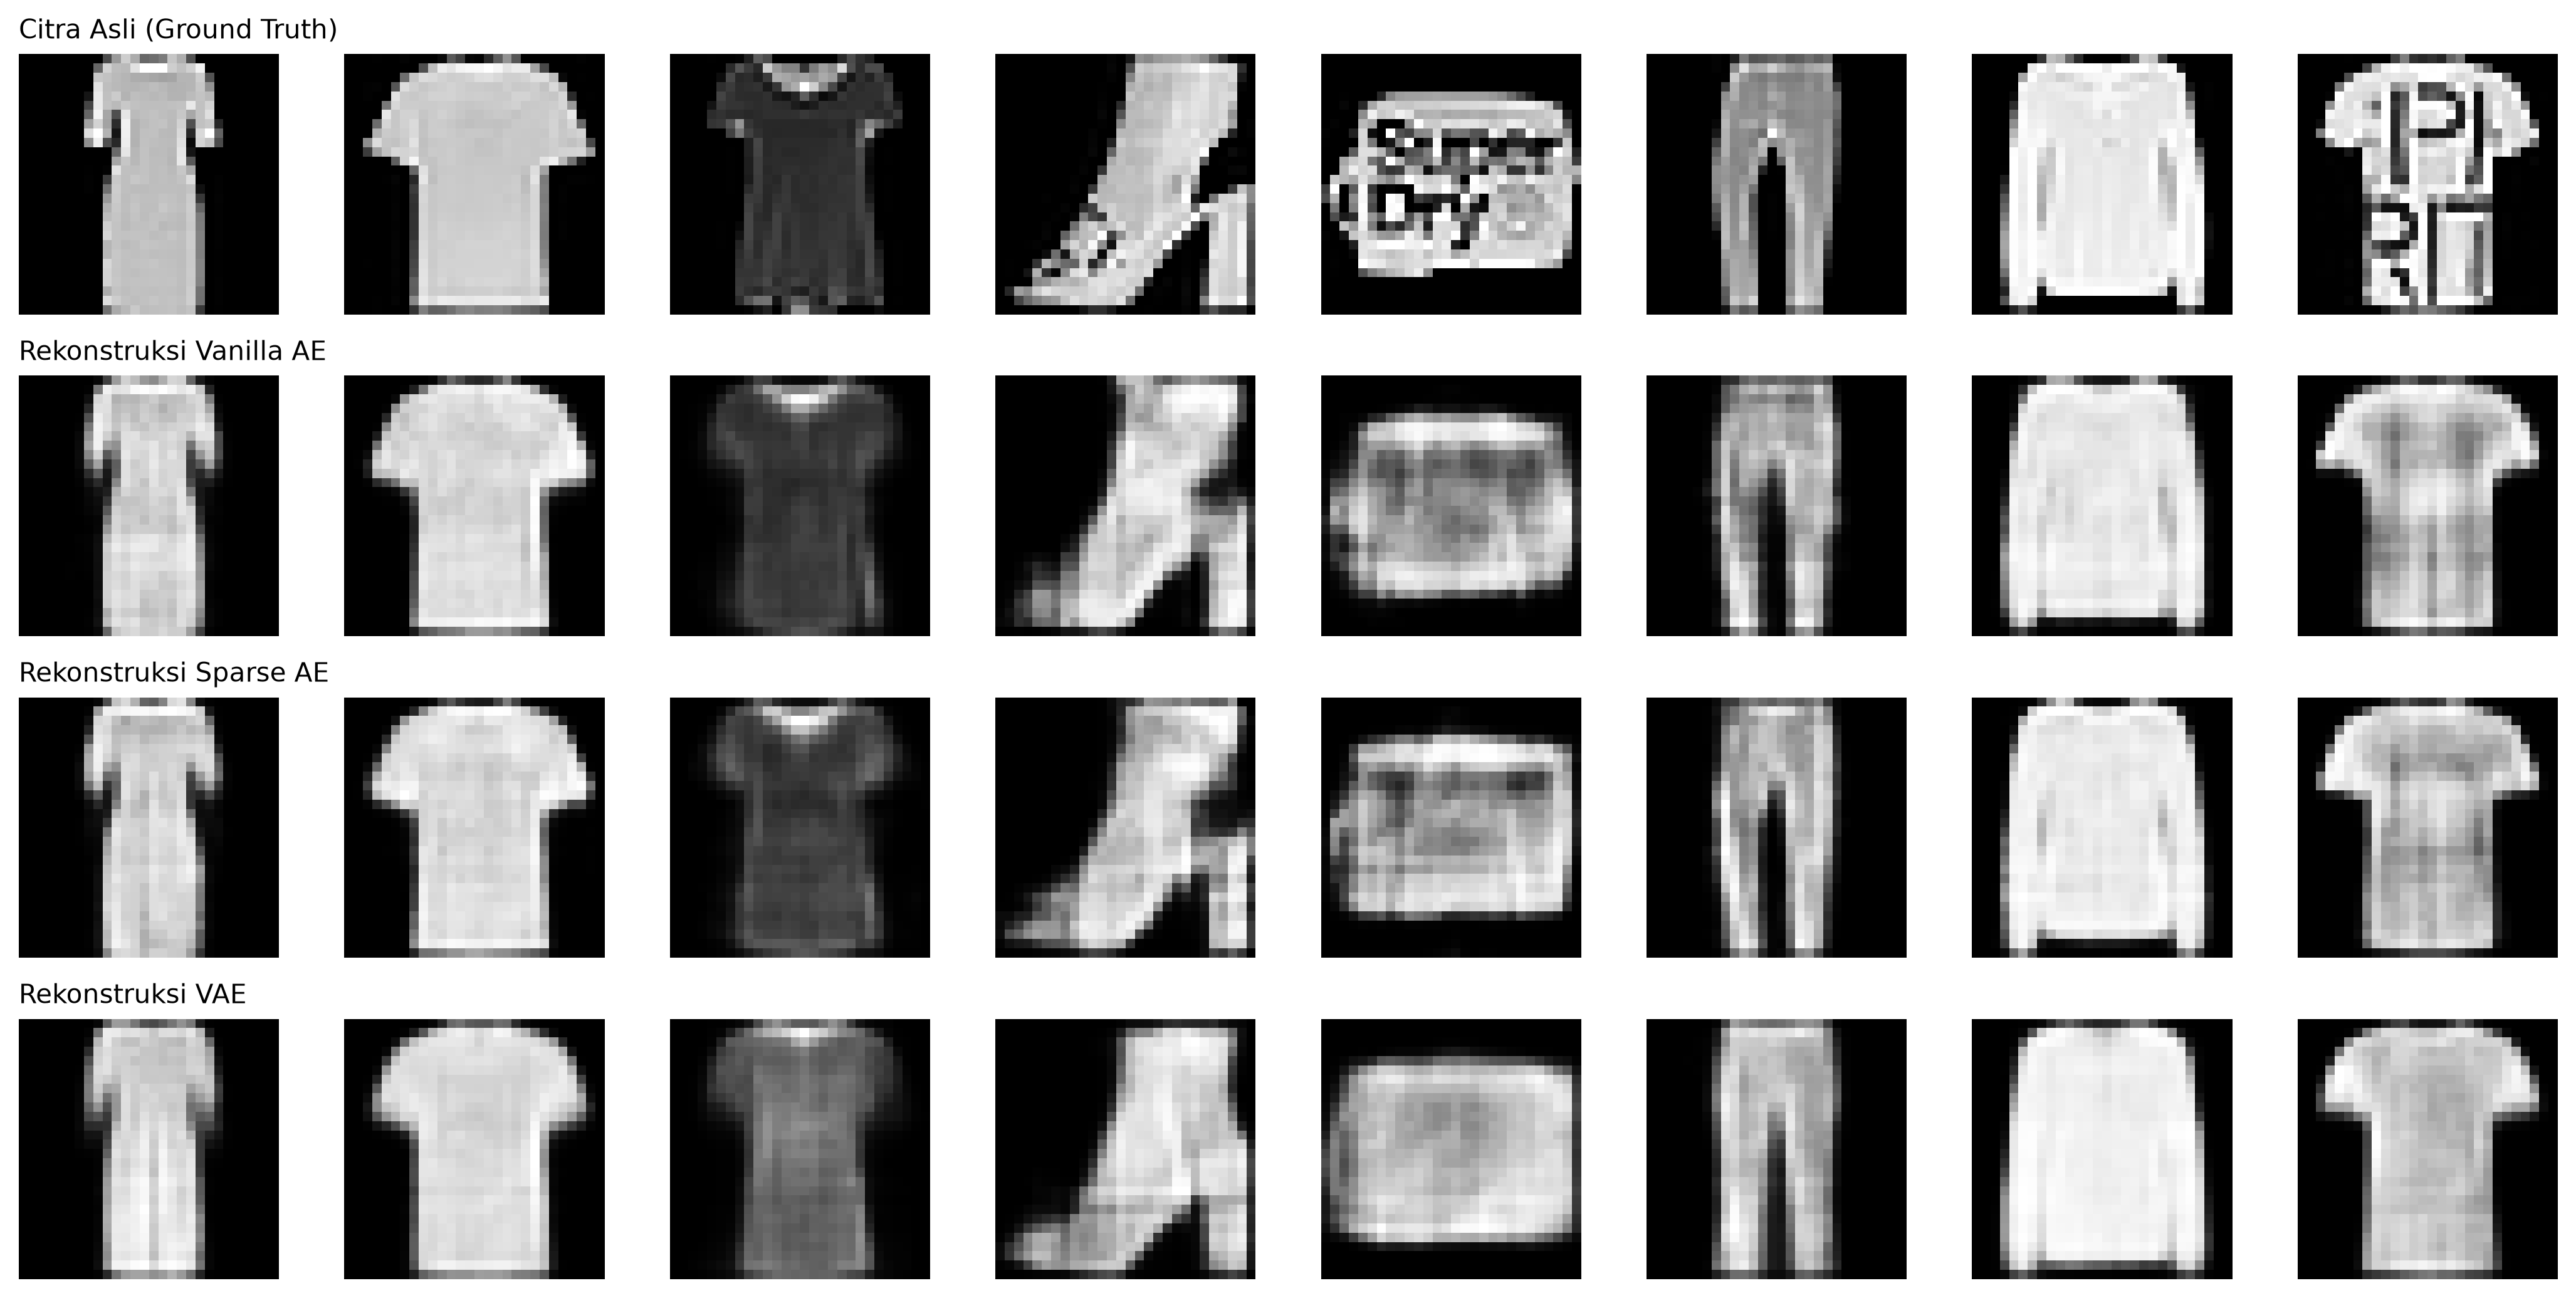

Figur 2: Grid Random Generative Sampling


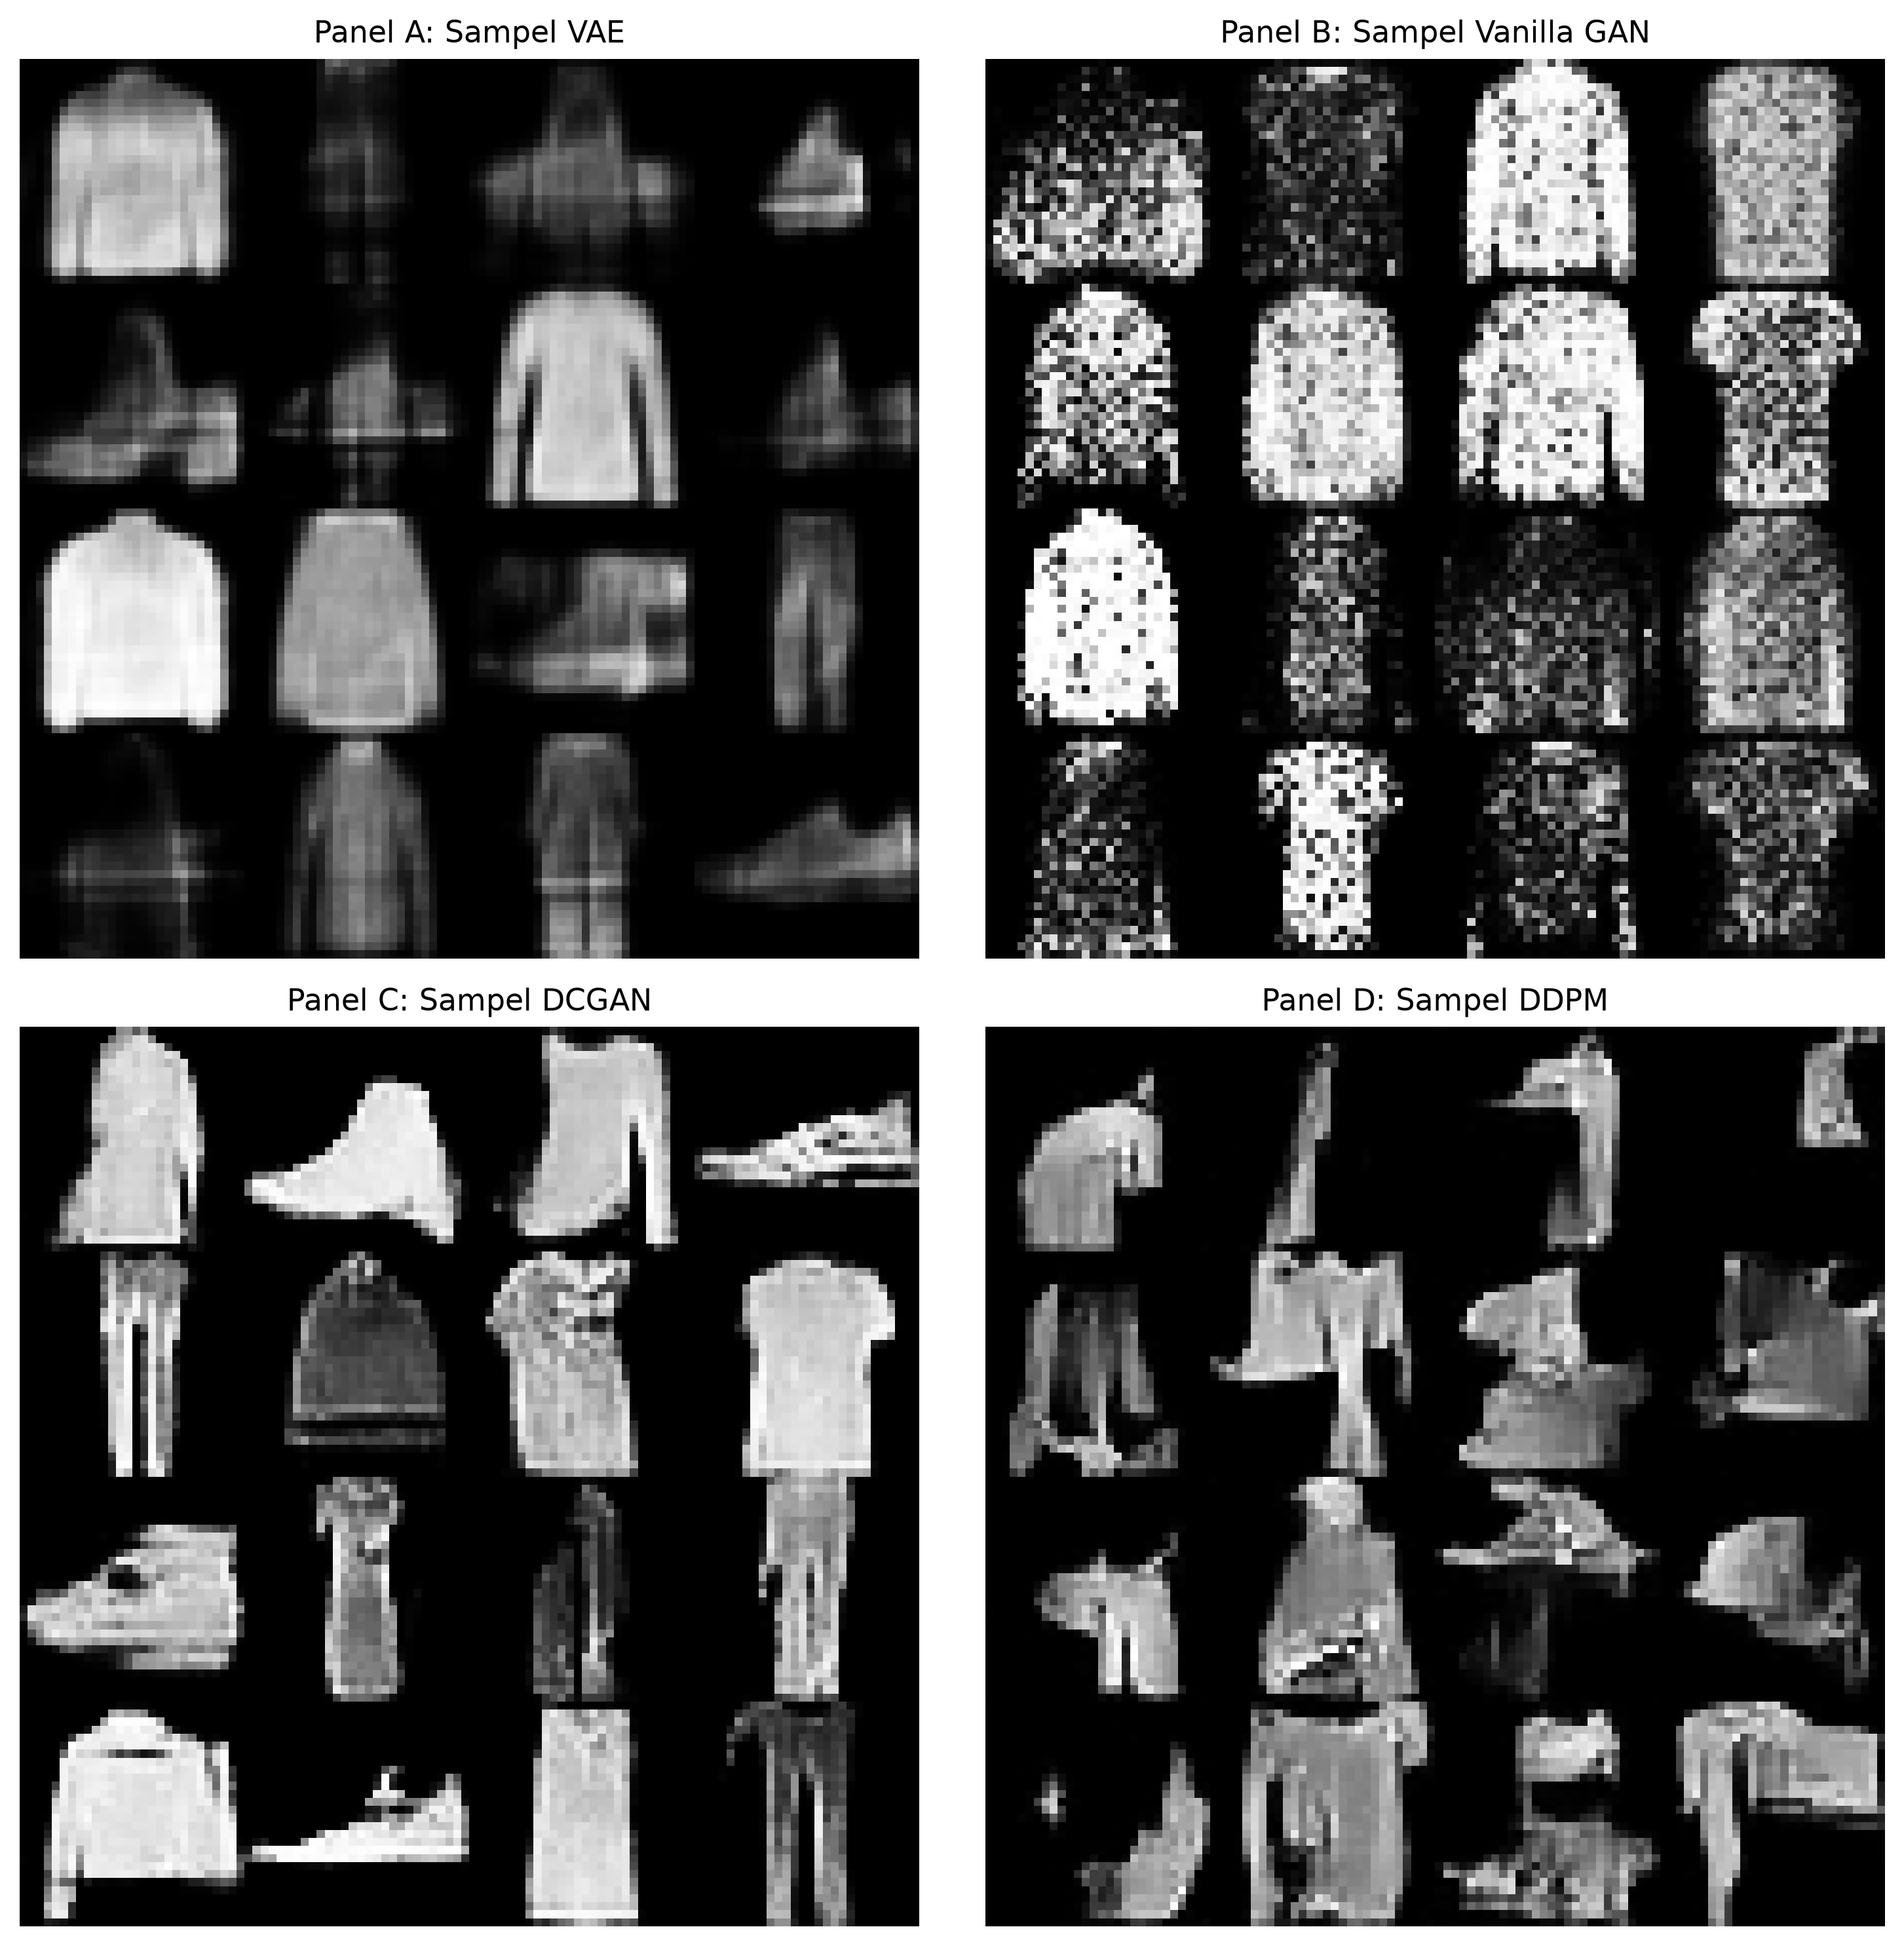

Figur 3: Bukti Batasan MLP Classifier


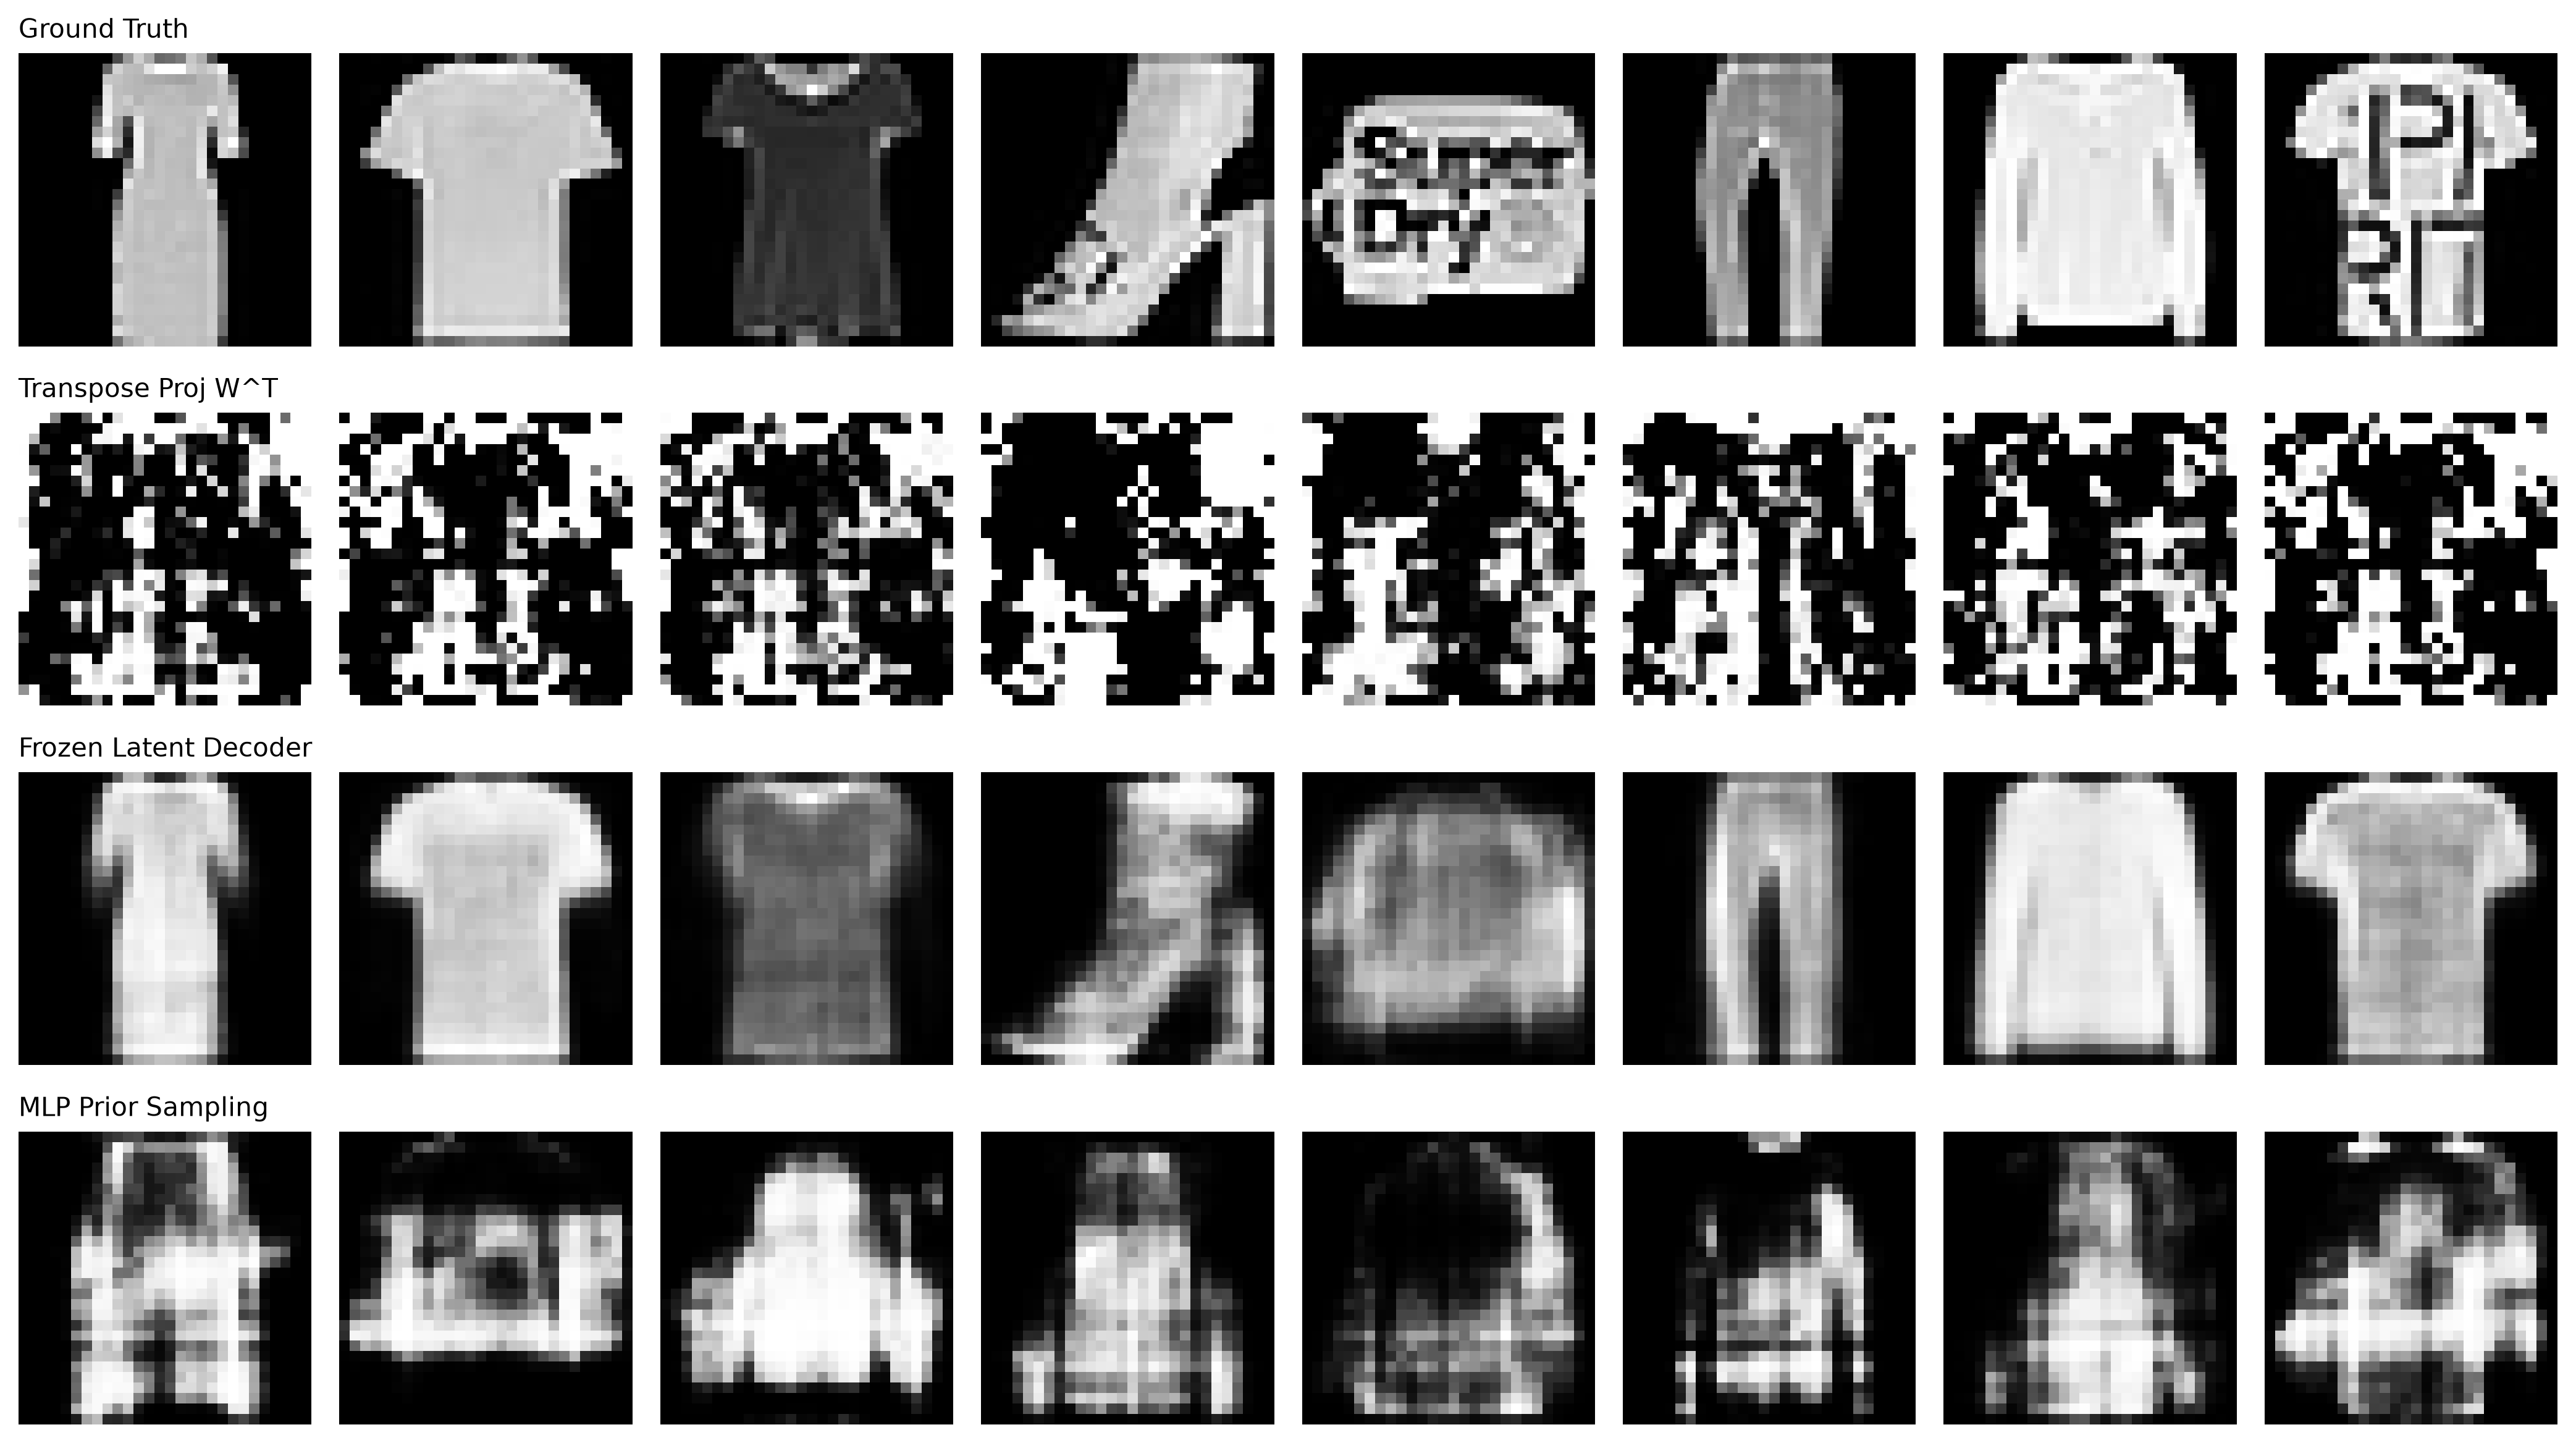

Figur 4: Linear Latent Space Interpolation


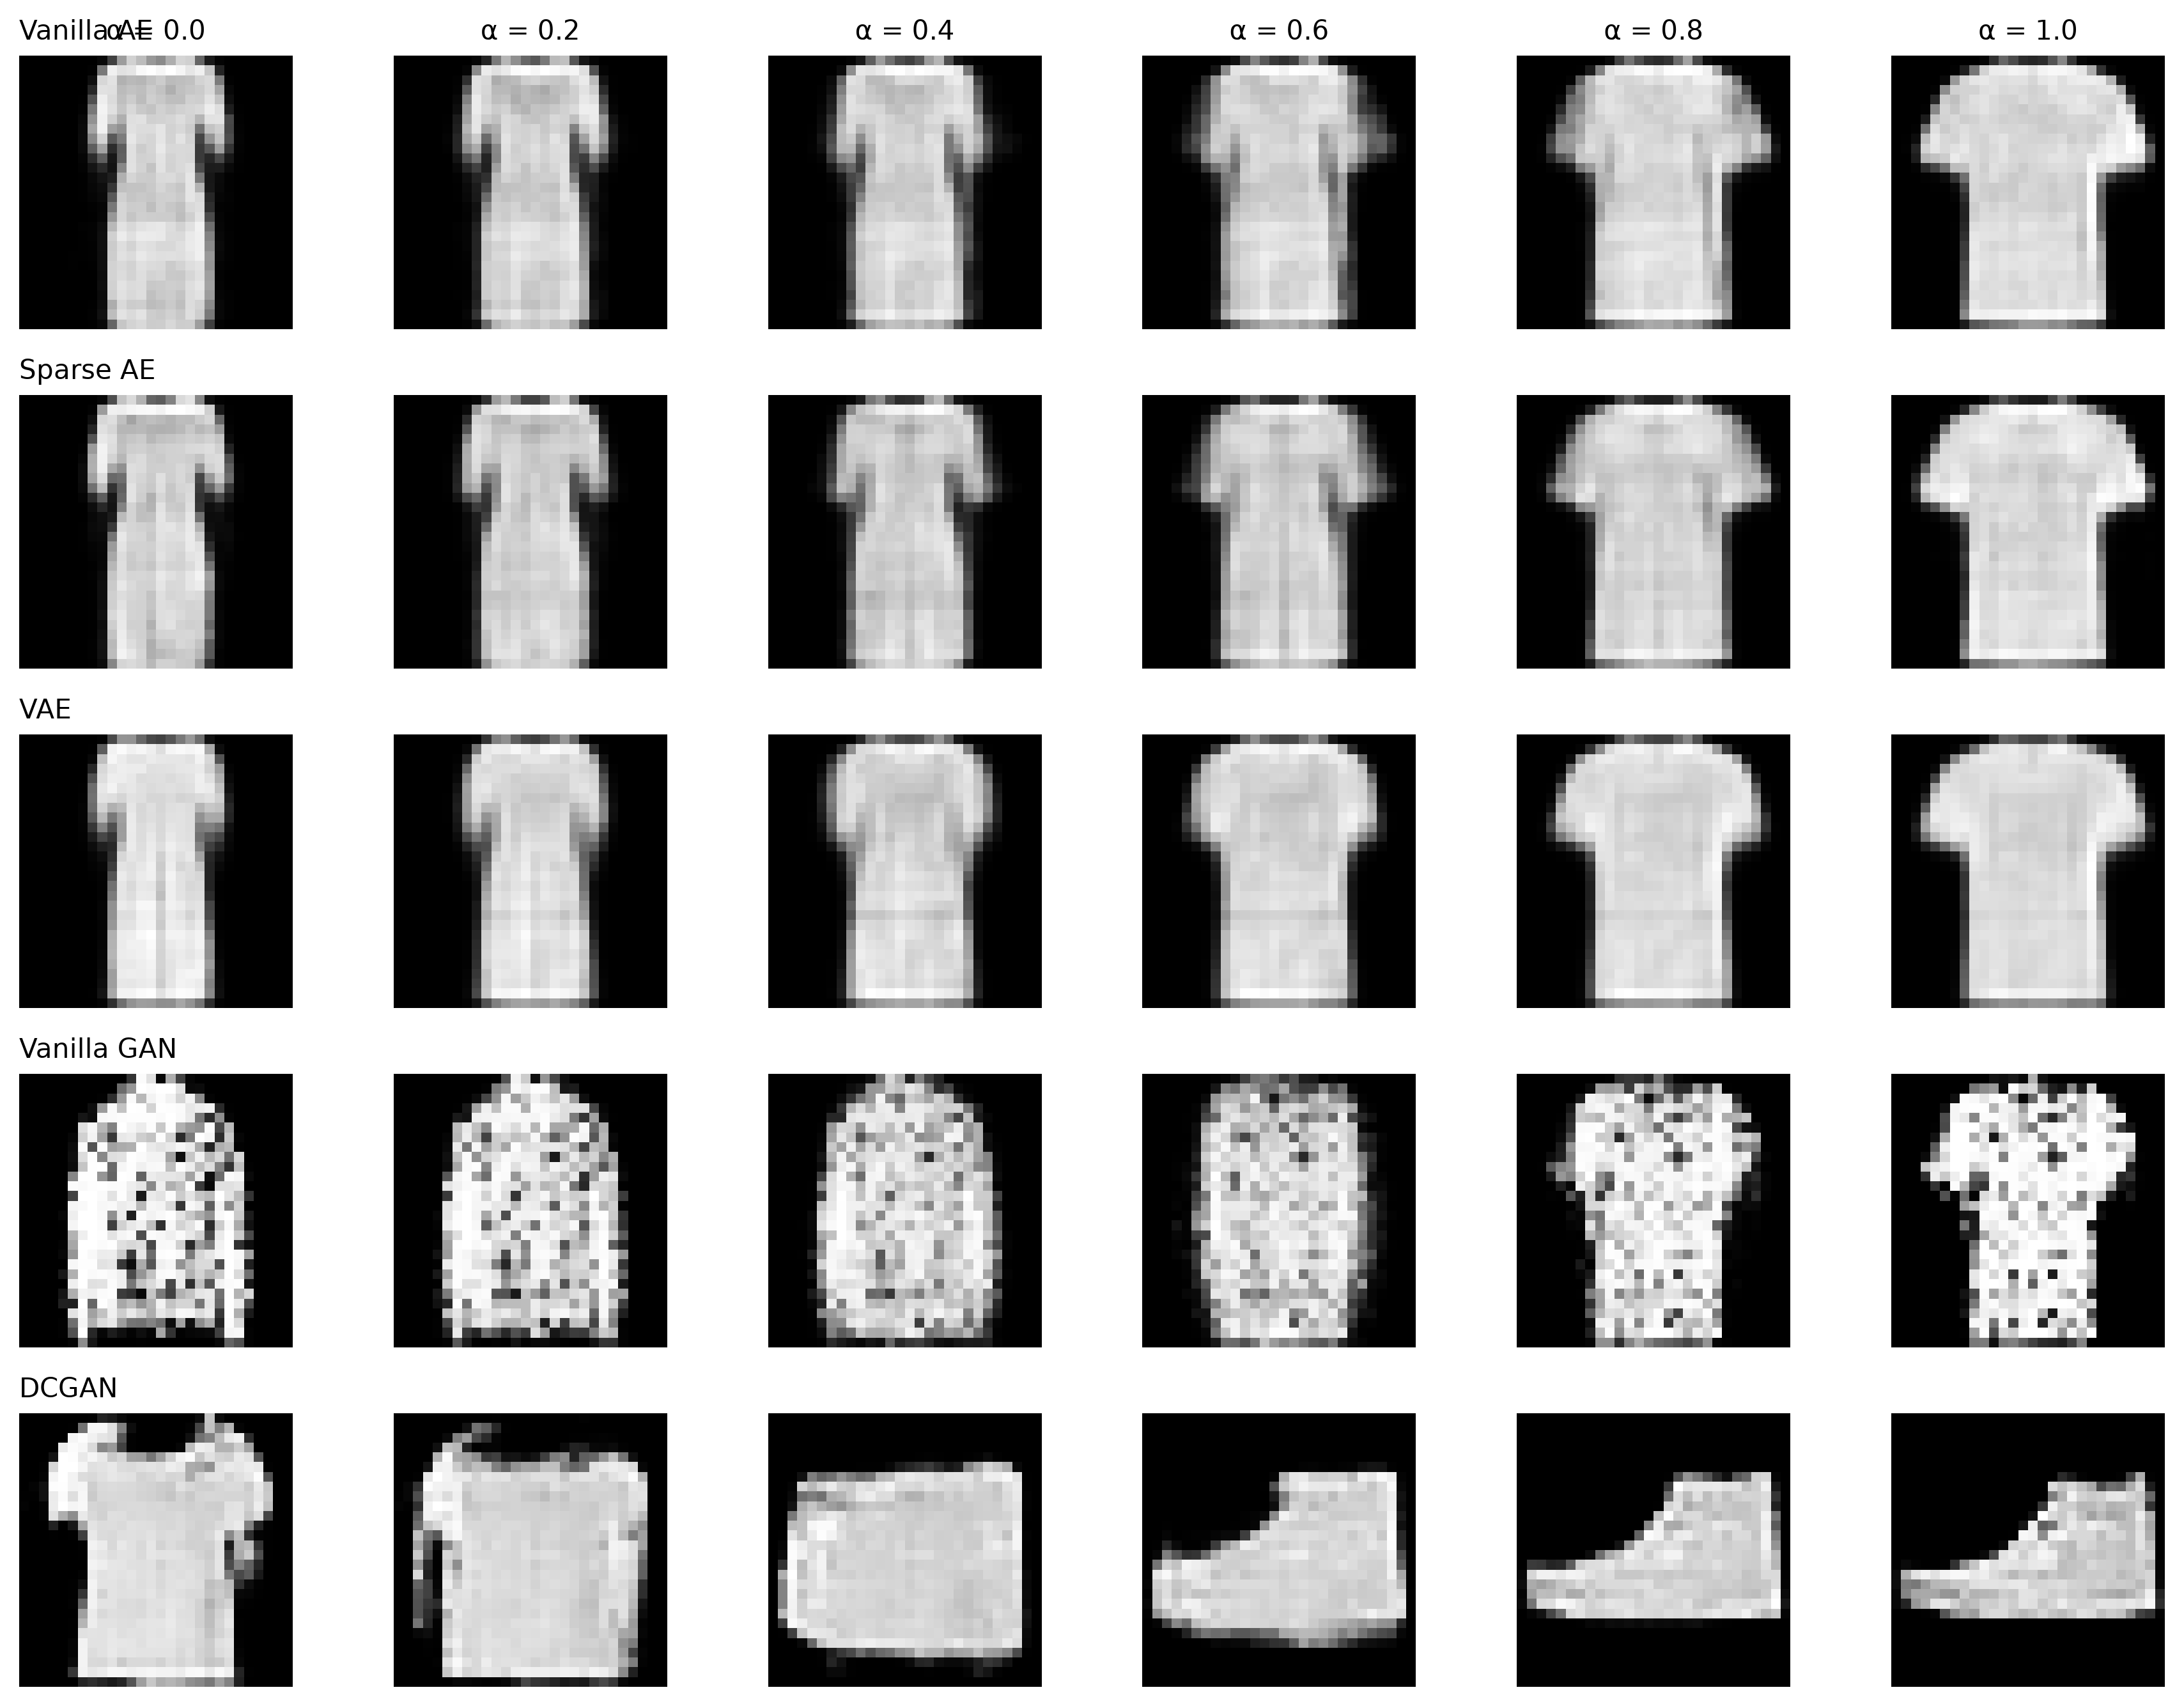

Figur 5: Kurva Loss & Trajektori Denoising DDPM


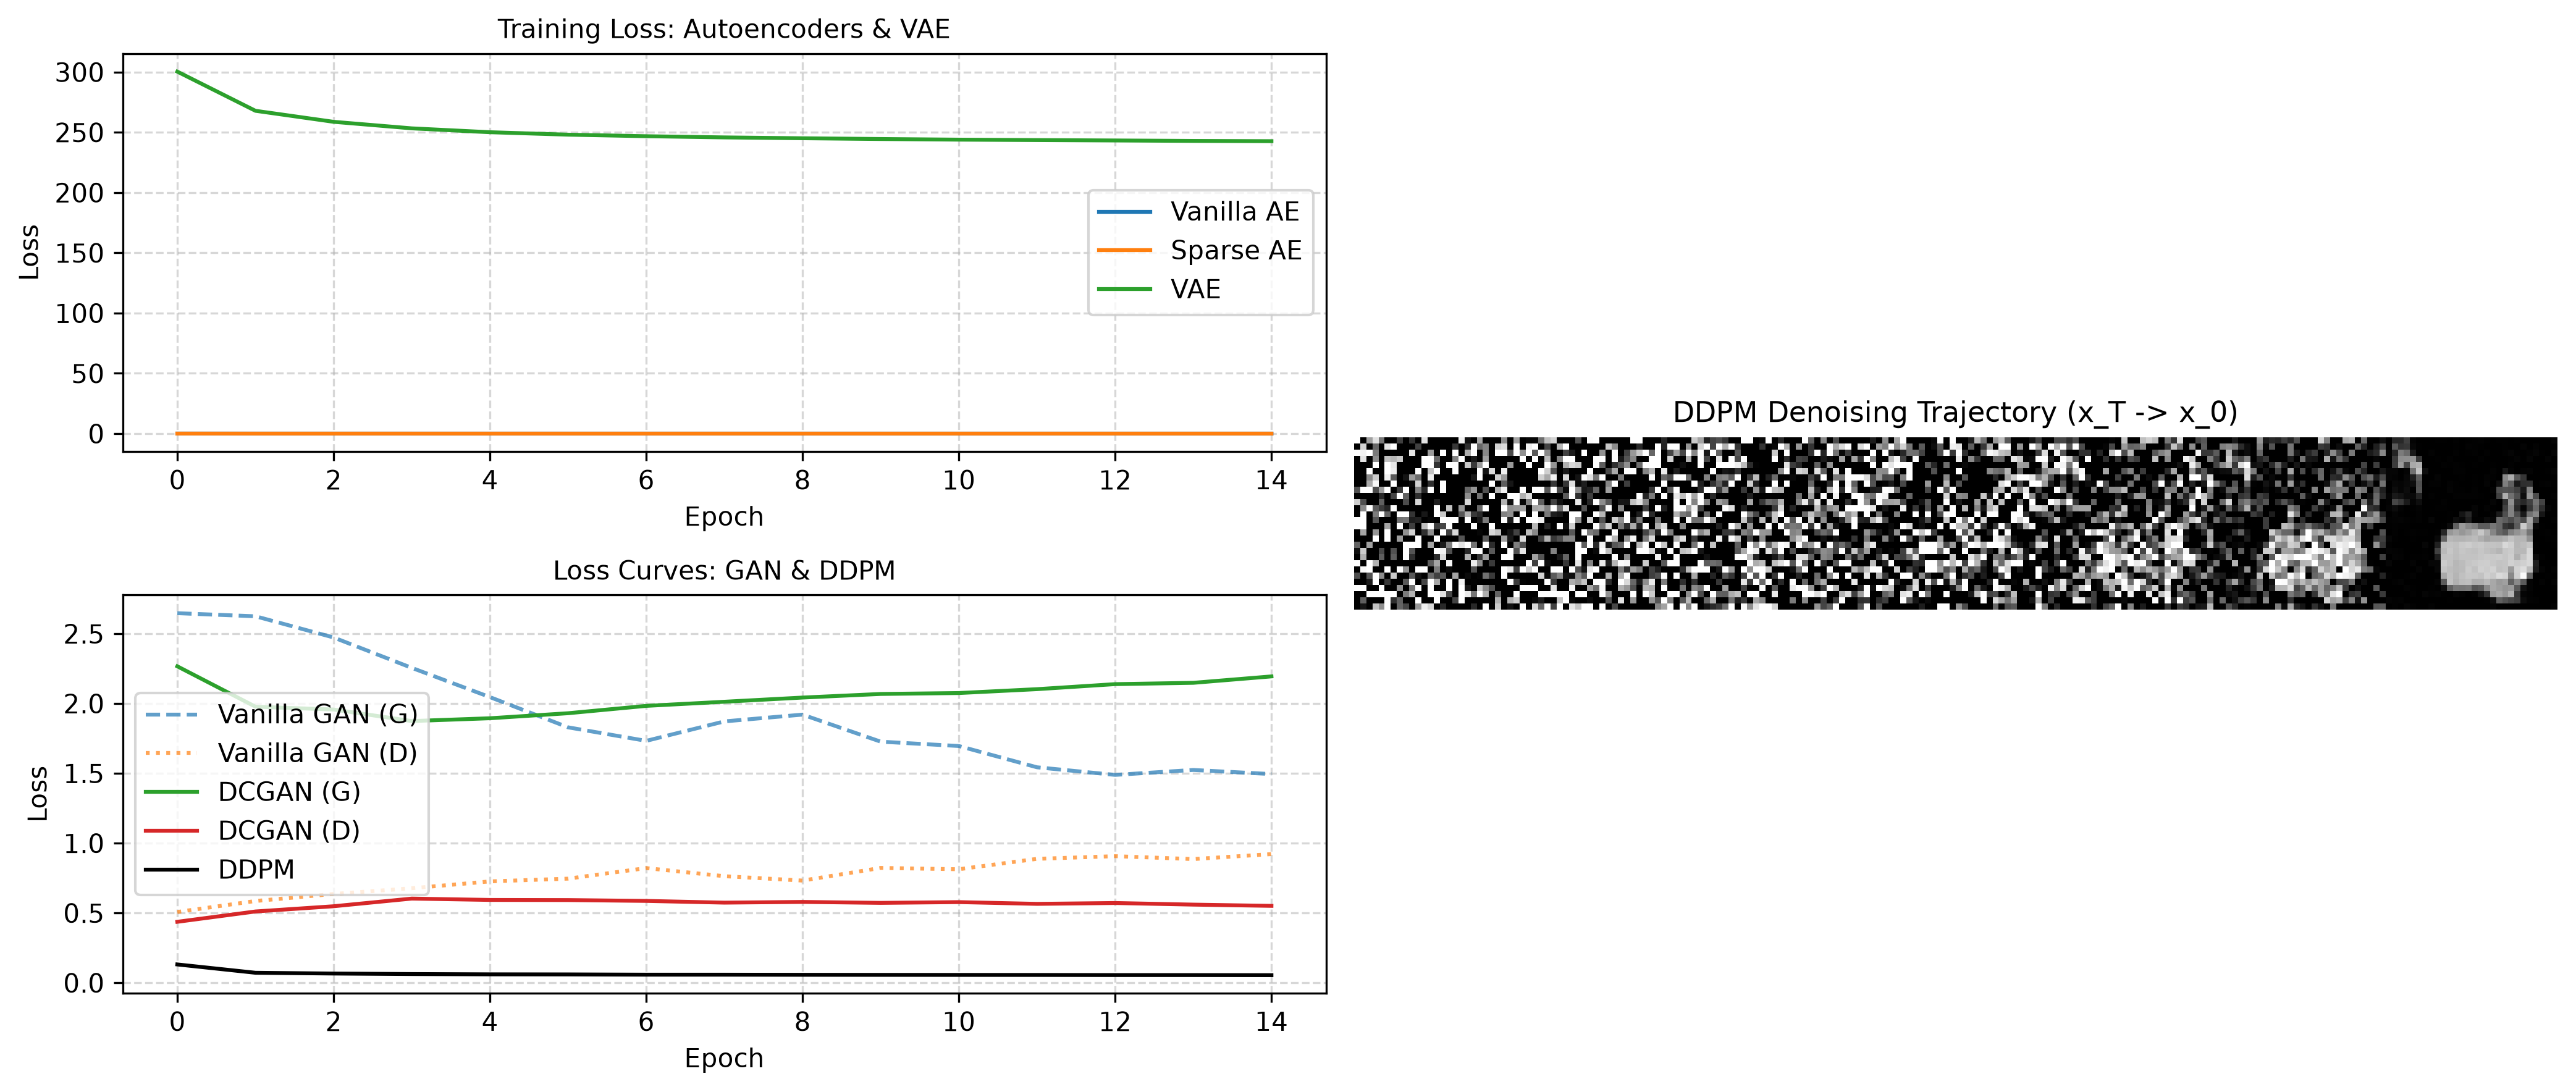

In [8]:
# 5. Tampilkan Seluruh Figur Hasil Eksperimen
from IPython.display import Image, display

figures = [
    ('Figur 1: Grid Rekonstruksi Side-by-Side', './figures/Figur_1_Rekonstruksi_SideBySide.png'),
    ('Figur 2: Grid Random Generative Sampling', './figures/Figur_2_Random_Generative_Sampling.png'),
    ('Figur 3: Bukti Batasan MLP Classifier', './figures/Figur_3_Batasan_MLP.png'),
    ('Figur 4: Linear Latent Space Interpolation', './figures/Figur_4_Latent_Interpolation.png'),
    ('Figur 5: Kurva Loss & Trajektori Denoising DDPM', './figures/Figur_5_LossCurves_and_DiffusionTrajectory.png'),
]

for title, path in figures:
    print(title)
    display(Image(filename=path))
